In [1]:
import sys
print(sys.executable)

/home/jupyter-23wh1a6610/.conda/envs/rediffinet/bin/python


In [2]:
%load_ext tensorboard

In [3]:
%tensorboard --logdir /home/jupyter-23wh1a6610/Major_Project/UNet_Output_Light_Benchmark/tensorboard

ERROR: Could not find `tensorboard`. Please ensure that your PATH
contains an executable `tensorboard` program, or explicitly specify
the path to a TensorBoard binary by setting the `TENSORBOARD_BINARY`
environment variable.

In [4]:
import os

os.environ["TENSORBOARD_BINARY"] = (
    "/home/jupyter-23wh1a6610/.conda/envs/rediffinet/bin/tensorboard"
)

os.environ["PATH"] = (
    "/home/jupyter-23wh1a6610/.conda/envs/rediffinet/bin:"
    + os.environ["PATH"]
)

print(os.environ["TENSORBOARD_BINARY"])

/home/jupyter-23wh1a6610/.conda/envs/rediffinet/bin/tensorboard


In [5]:
%reload_ext tensorboard

In [6]:
%tensorboard --logdir /home/jupyter-23wh1a6610/Major_Project/UNet_Output_Light_BF16/tensorboard

In [7]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
import os

logdir = "/home/jupyter-23wh1a6610/Major_Project/UNet_Output_Light_Benchmark/tensorboard/fold_0"

files = os.listdir(logdir)
print(files)

['events.out.tfevents.1788286521.ai.2035627.0', 'events.out.tfevents.1788284464.ai.2033617.0', 'events.out.tfevents.1788319074.ai.2056606.0', 'events.out.tfevents.1788314688.ai.2051218.0']


In [8]:
ea = EventAccumulator(logdir)
ea.Reload()

print(ea.Tags()["scalars"])

['Model/Total_Parameters', 'Model/Trainable_Parameters', 'Train/Batch_Loss', 'Train/Loss', 'Train/MSE_Loss', 'Train/BCE_Loss', 'Train/Learning_Rate', 'Run/Epoch', 'Performance/Epoch_Time_Seconds', 'Performance/Train_Time_Seconds', 'Performance/Validation_Time_Seconds', 'Performance/Peak_GPU_Memory_GB', 'Performance/Samples_Per_Second', 'Validation/Loss', 'Validation/WT_Dice', 'Validation/TC_Dice', 'Validation/ET_Dice', 'Validation/Mean_Dice', 'Best/Mean_Dice', 'Best/WT_Dice', 'Best/TC_Dice', 'Best/ET_Dice', 'EarlyStopping/Counter']


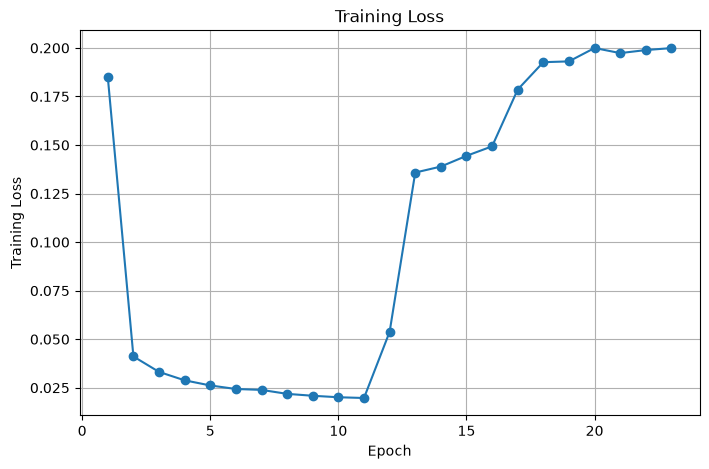

In [9]:
import matplotlib.pyplot as plt

values = ea.Scalars("Train/Loss")

epochs = [x.step for x in values]
losses = [x.value for x in values]

plt.figure(figsize=(8,5))
plt.plot(epochs, losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss")
plt.grid()
plt.show()

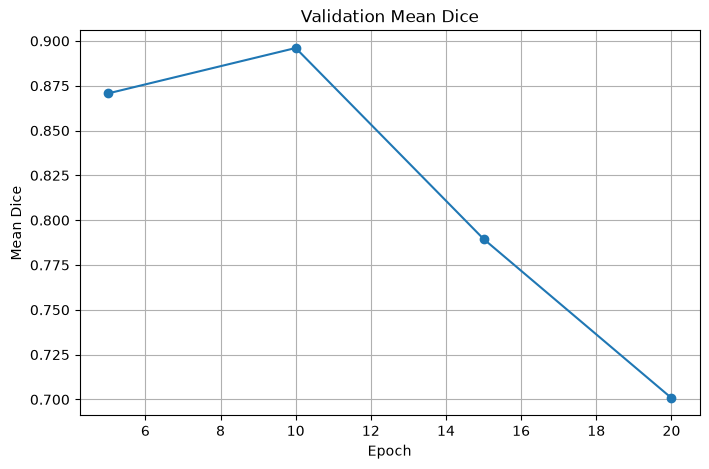

In [10]:
values = ea.Scalars("Validation/Mean_Dice")

epochs = [x.step for x in values]
dice = [x.value for x in values]

plt.figure(figsize=(8,5))
plt.plot(epochs, dice, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Mean Dice")
plt.title("Validation Mean Dice")
plt.grid()
plt.show()

In [11]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

logdir = "/home/jupyter-23wh1a6610/Major_Project/UNet_Output_Light_Benchmark/tensorboard/fold_0"

ea = EventAccumulator(logdir)
ea.Reload()

for x in ea.Scalars("Train/Learning_Rate"):
    print(x.step, x.value)

1 5.999999848427251e-05
2 5.9699999837903306e-05
3 5.9401500038802624e-05
4 5.910449181101285e-05
5 5.8808971516555175e-05
6 5.851492460351437e-05
7 5.8222351071890444e-05
8 5.7931240007746965e-05
9 5.764158413512632e-05
10 5.73533761780709e-05
11 5.706660886062309e-05
12 5.6781274906825274e-05
13 5.649736704071984e-05
14 5.621488162432797e-05
15 5.593380774371326e-05
16 5.5654138122918084e-05
17 5.537586912396364e-05
18 5.50989898329135e-05
19 5.482349297381006e-05
20 5.454937490867451e-05
21 5.427662836154923e-05
22 5.400524605647661e-05
23 5.373522071749903e-05
24 5.346654506865889e-05
25 5.319921183399856e-05


In [12]:
for tag in ["Train/MSE_Loss", "Train/BCE_Loss"]:
    print("\n", tag)
    for x in ea.Scalars(tag):
        print(x.step, x.value)


 Train/MSE_Loss
1 0.055636730045080185
2 0.012677068822085857
3 0.010769544169306755
4 0.009541427716612816
5 0.008688309229910374
6 0.008134628646075726
7 0.00797946099191904
8 0.007316955365240574
9 0.006988834589719772
10 0.006712440401315689
11 0.006500135641545057
12 0.012265370227396488
13 0.03352748602628708
14 0.03449255973100662
15 0.03631037846207619
16 0.03798693045973778
17 0.048747364431619644
18 0.05401965230703354
19 0.053891465067863464
20 0.056529734283685684
21 0.05526949092745781
22 0.055908072739839554
23 0.0561465360224247
24 0.05783790722489357
25 0.06301514804363251

 Train/BCE_Loss
1 0.23247458040714264
2 0.05149313807487488
3 0.04122309386730194
4 0.03573863208293915
5 0.0324518084526062
6 0.03016512840986252
7 0.029590561985969543
8 0.027047621086239815
9 0.025836793705821037
10 0.02490418776869774
11 0.024474341422319412
12 0.06980591267347336
13 0.17487865686416626
14 0.17873001098632812
15 0.18559002876281738
16 0.19161438941955566
17 0.22724506258964539
1

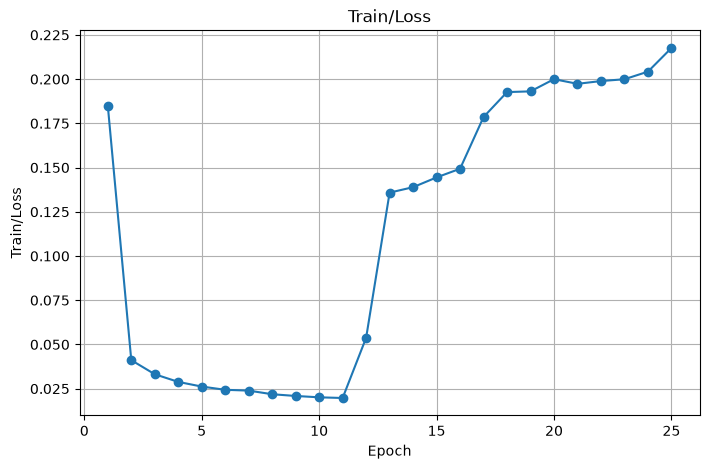

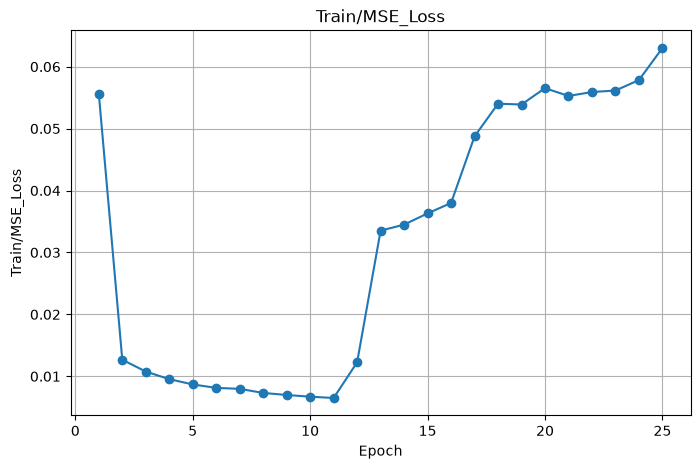

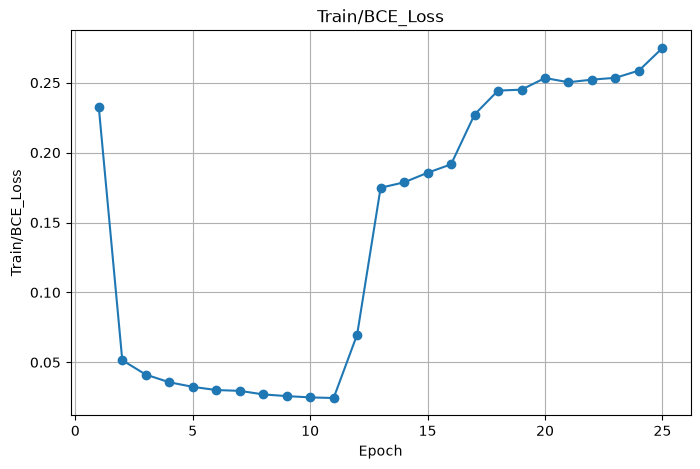

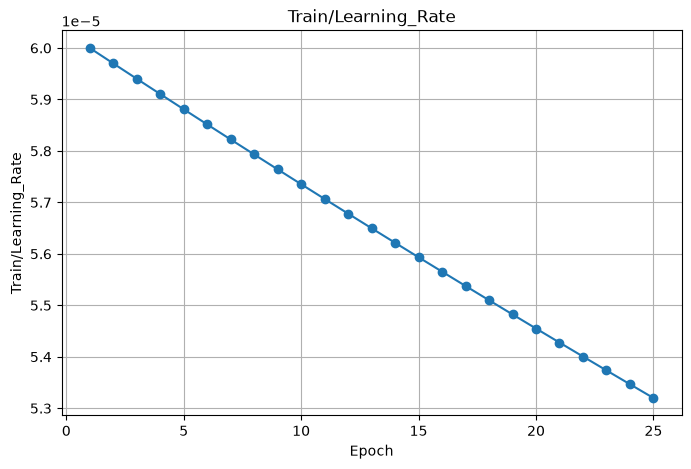

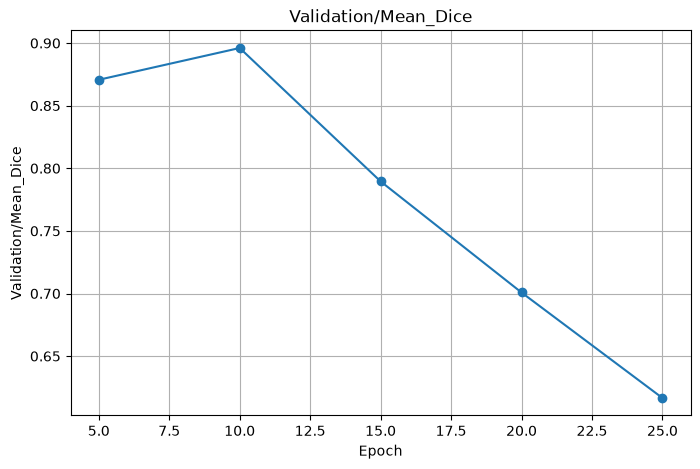

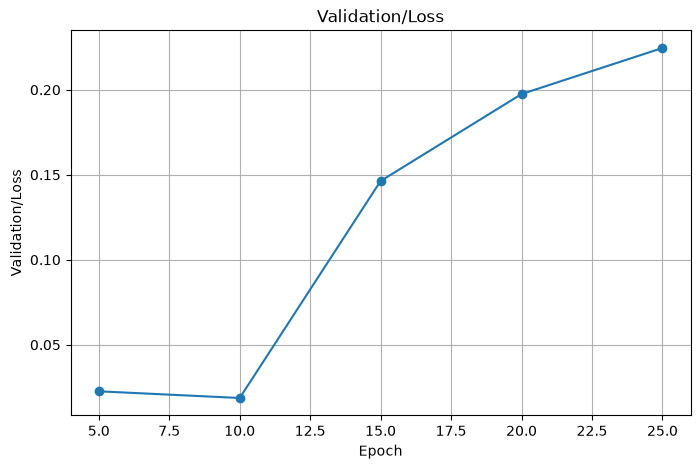

In [13]:
import matplotlib.pyplot as plt

def plot_tb(tag):
    data = ea.Scalars(tag)
    x = [v.step for v in data]
    y = [v.value for v in data]

    plt.figure(figsize=(8, 5))
    plt.plot(x, y, marker="o")
    plt.xlabel("Epoch")
    plt.ylabel(tag)
    plt.title(tag)
    plt.grid()
    plt.show()

plot_tb("Train/Loss")
plot_tb("Train/MSE_Loss")
plot_tb("Train/BCE_Loss")
plot_tb("Train/Learning_Rate")
plot_tb("Validation/Mean_Dice")
plot_tb("Validation/Loss")